# San Diego ERA5 Initial Analysis

add `~/.cdsapirc` file with CDS API key

   !pip install "cdsapi>=0.7.2" netcdf4

In [4]:
   !pip install "cdsapi>=0.7.2" netcdf4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 97.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 69.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [cdsapi]


In [5]:
# where the api key was

In [11]:
from importlib.metadata import version
print(version("cdsapi"))

0.7.7


In [12]:
import glob, os, zipfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "era5_sandiego"
AREA = [33.5, -117.6, 32.5, -116.1]
os.makedirs(DATA_DIR, exist_ok=True)

In [13]:
# requeest data for each year
RUN_DOWNLOAD = True

VARIABLES = [
    "10m_u_component_of_wind",
    "10m_v_component_of_wind",
    "total_precipitation",
]

import cdsapi
client = cdsapi.Client()

for month in range(1, 13):
    tag = f"2024_{month:02d}"
    if glob.glob(f"{DATA_DIR}/era5_{tag}*"):
        continue
    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": ["reanalysis"],
            "variable": VARIABLES,
            "year": ["2024"],
            "month": [f"{month:02d}"],
            "day": [f"{d:02d}" for d in range(1, 32)],
            "time": [f"{h:02d}:00" for h in range(24)],
            "area": AREA,
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        f"{DATA_DIR}/era5_{tag}.nc",
    )

Exception: Missing/incomplete configuration file: /root/.cdsapirc

In [ ]:
import re

# unzipping
for f in glob.glob(f"{DATA_DIR}/*.nc"):
    if zipfile.is_zipfile(f):
        folder = f.replace(".nc", "_unz")
        with zipfile.ZipFile(f) as z:
            z.extractall(folder)
        os.rename(f, f + ".zip")

# grouping by month
groups = {}
for f in sorted(glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)):
    m = re.search(r"era5_(\d{4})_(\d{2})", f)
    if m:
        groups.setdefault(m.group(0), []).append(f)

print(f"Found {len(groups)} months:", sorted(groups))

monthly = []
for key, files in sorted(groups.items()):
    parts = [xr.open_dataset(f) for f in files]
    monthly.append(xr.merge(parts, compat="override", join="override"))

# building dataseet
time_dim = "valid_time" if "valid_time" in monthly[0].dims else "time"
ds = xr.concat(monthly, dim=time_dim)
if time_dim == "valid_time":
    ds = ds.rename({"valid_time": "time"})
ds = ds.drop_vars([v for v in ["number", "expver"] if v in ds.coords])
ds = ds.sortby("time").sel(time=slice("2024-01-01", "2024-12-31 23:00"))
ds

In [10]:
# putting tgt precipitation spikes

POINT_MODE = "max"   # "max" or "mean"

tp_in = ds["tp"] * 39.3701
if POINT_MODE == "max":
    p1 = tp_in.max(["latitude", "longitude"]).to_series()
    p3 = tp_in.rolling(time=3).sum().max(["latitude", "longitude"]).to_series()
else:
    p1 = tp_in.mean(["latitude", "longitude"]).to_series()
    p3 = tp_in.mean(["latitude", "longitude"]).rolling(time=3).sum().to_series()

ev1 = p1[(p1 >= 1.2) & (p1 <= 1.5)]
ev1_hi = p1[p1 > 1.5]
ev3 = p3[(p3 >= 1.6) & (p3 <= 2.4)]
ev3_hi = p3[p3 > 2.4]

print(f"1-hr events 1.2-1.5 in: {len(ev1)}   (above 1.5 in: {len(ev1_hi)})")
print(f"3-hr events 1.6-2.4 in: {len(ev3)}   (above 2.4 in: {len(ev3_hi)})")
print(f"Max 1-hr: {p1.max():.2f} in on {p1.idxmax()}")
print(f"Max 3-hr: {p3.max():.2f} in on {p3.idxmax()}")

NameError: name 'ds' is not defined

NameError: name 'p1' is not defined

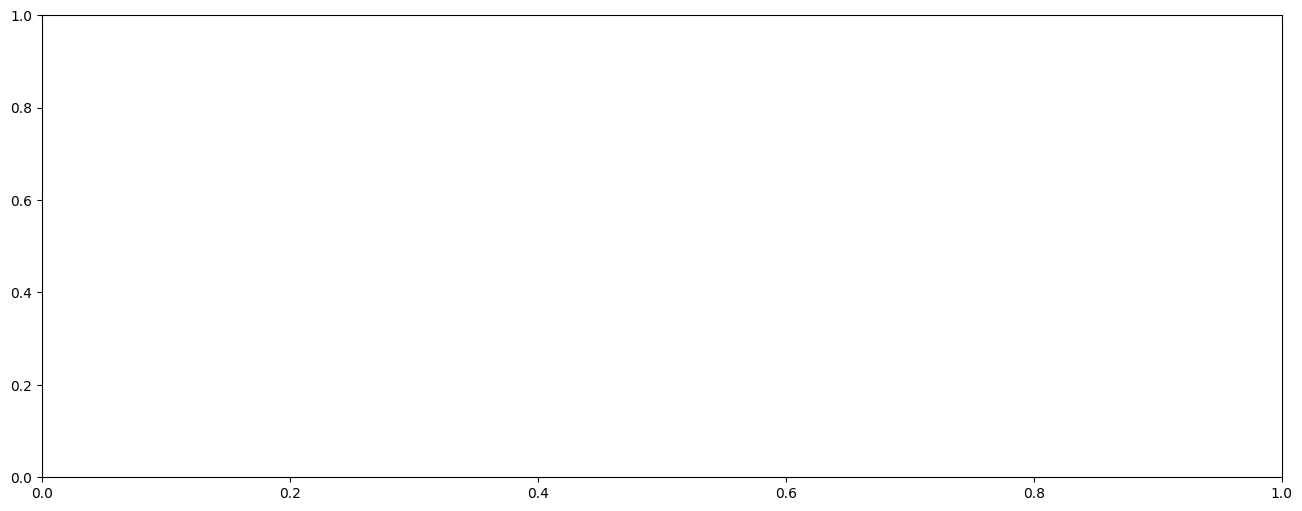

In [9]:
fig, ax = plt.subplots(figsize=(16, 6))

daily_max = p1.resample("D").max()
ax.vlines(daily_max.index, 0, daily_max.values, color="lightgray", lw=0.6,
          label="Daily max 1-hr precip")

# extreme markers
ax.axhspan(1.2, 1.5, color="orange", alpha=0.15, label="1-hr band (1.2–1.5 in)")
ax.axhspan(1.6, 2.4, color="red", alpha=0.10, label="3-hr band (1.6–2.4 in)")

ax.scatter(ev1.index, ev1.values, s=60, color="orange", edgecolor="k", zorder=3,
           label=f"1-hr 1.2–1.5 in (n={len(ev1)})")
ax.scatter(ev1_hi.index, ev1_hi.values, s=60, marker="^", color="darkorange", edgecolor="k",
           zorder=3, label=f"1-hr > 1.5 in (n={len(ev1_hi)})")
ax.scatter(ev3.index, ev3.values, s=60, marker="D", color="red", edgecolor="k", zorder=3,
           label=f"3-hr 1.6–2.4 in (n={len(ev3)})")
ax.scatter(ev3_hi.index, ev3_hi.values, s=70, marker="*", color="darkred", edgecolor="k",
           zorder=3, label=f"3-hr > 2.4 in (n={len(ev3_hi)})")

ax.set_ylabel("Precipitation (inches)")
ax.set_xlabel("Year")
ax.set_title(f"San Diego County: Extreme Precipitation Spikes of 2024")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

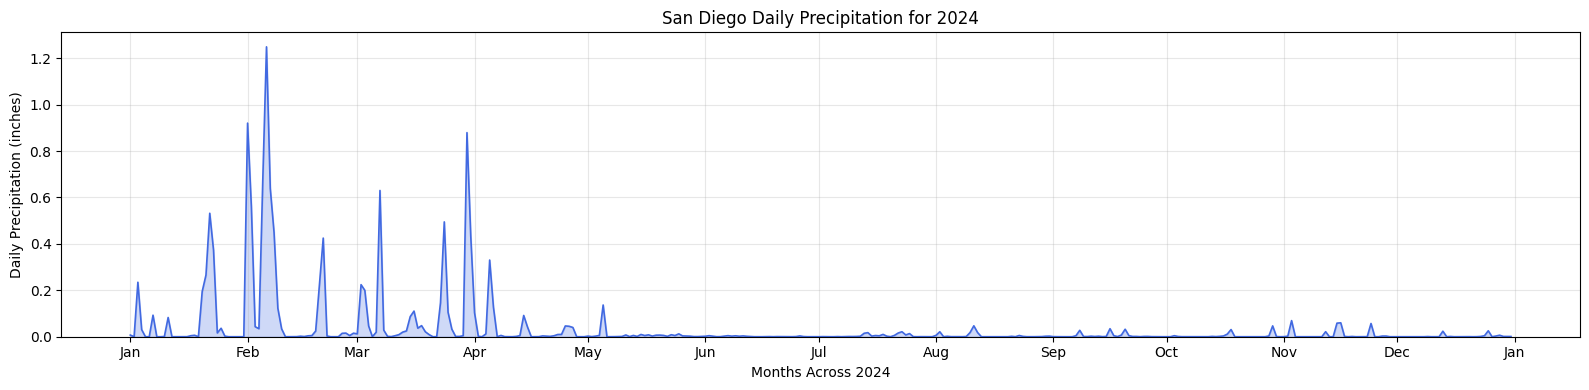

Total for 2024: 12.99 in
Wettest day: 2024-02-06 (1.25 in)


In [ ]:
# graphing daily precip over 2024

precip_d = (ds["tp"] * 39.3701).mean(["latitude", "longitude"]).resample(time="D").sum().to_series()

fig3, ax3 = plt.subplots(figsize=(16, 4))
ax3.plot(precip_d.index, precip_d.values, color="royalblue", lw=1.2)
ax3.fill_between(precip_d.index, precip_d.values, color="royalblue", alpha=0.25)
ax3.set_ylabel("Daily Precipitation (inches)")
ax3.set_xlabel("Months Across 2024")
ax3.set_title("San Diego Daily Precipitation for 2024")
ax3.xaxis.set_major_locator(mdates.MonthLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax3.set_ylim(bottom=0)
ax3.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total for 2024: {precip_d.sum():.2f} in")
print(f"Wettest day: {precip_d.idxmax().date()} ({precip_d.max():.2f} in)")

In [14]:
# zooming in onto Jan flood timeline

storm = (ds["tp"] * 39.3701).max(["latitude", "longitude"]).sel(time=slice("2024-01-21", "2024-01-23"))

ax = storm.to_series().plot(figsize=(14, 4), title="Hourly Precipitation for January 21-23, 2024 (in/hr)")
ax.set_ylabel("Peak Precipitation (inches per hour)")
ax.set_xlabel("Time (12 hr Increments)")

print(f"Peak hourly: {storm.max().item():.2f} in")
print(f"Peak 3-hr: {storm.rolling(time=3).sum().max().item():.2f} in")

NameError: name 'ds' is not defined